In [1]:
import sys

sys.argv = [""]  # to avoid issues with Jupyter and argparse

In [2]:
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import arviz as az
import xarray
from scipy.stats import qmc
from ipywidgets import interact, IntSlider
import matplotlib.pyplot as plt
from pathlib import Path
import json
import ICIW_Plots

plt.style.use("ICIWstyle")

In [3]:
from HSA_Cam_D_007 import (
    calculate_partial_pressures,
    predict_funs,
    JSD_marginal,
    JSD_between_predictions,
    calculate_disagreement,
    LHSDOE,
    generate_synthetic_data,
    find_opt_candidate,
)
from HSA_Mo_D_001_numpyro import validate_against_holdout as validate_Mo1
from HSA_Mo_D_002_numpyro import validate_against_holdout as validate_Mo2
from HSA_Mo_D_003_numpyro import validate_against_holdout as validate_Mo3
from HSA_Mo_D_004_numpyro import validate_against_holdout as validate_Mo4

validate_funs = {
    "Mo1": validate_Mo1,
    "Mo2": validate_Mo2,
    "Mo3": validate_Mo3,
    "Mo4": validate_Mo4,
}

In [4]:
# exp_run_name = "scornful-placebo"  # VI small test
exp_run_name = "considerable-humor"  # full run with optimized settings
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"

trace_files = {
    "Mo1": sorted(data_path.glob("Mo1_trace_*.nc")),
    "Mo2": sorted(data_path.glob("Mo2_trace_*.nc")),
    "Mo3": sorted(data_path.glob("Mo3_trace_*.nc")),
    "Mo4": sorted(data_path.glob("Mo4_trace_*.nc")),
}

In [5]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)
display(len(exp_summary["trials"]))  # display last trial summary

4

In [6]:
proposals = jnp.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = jnp.array(exp_summary["trials"][-1]["observed"]["y"])

In [7]:
idatas = {
    "Mo1": [],
    "Mo2": [],
    "Mo3": [],
    "Mo4": [],
}

errored_files = []

for Mo, Mo_trace_files in trace_files.items():
    for i, Mo_trace_file in enumerate(Mo_trace_files):
        print(f"Loading {Mo_trace_file}")
        try:
            Mo_idata = az.from_netcdf(Mo_trace_file)
            idatas[Mo].append(Mo_idata)
        except Exception as e:
            idatas[Mo].append(None)
            errored_files.append((Mo, i, Mo_trace_file))
            print(f"Could not load {Mo_trace_file}: {e}")
            continue

Loading data/considerable-humor/Mo1_trace_000.nc
Loading data/considerable-humor/Mo1_trace_001.nc
Loading data/considerable-humor/Mo1_trace_002.nc
Loading data/considerable-humor/Mo1_trace_003.nc
Loading data/considerable-humor/Mo1_trace_004.nc
Loading data/considerable-humor/Mo2_trace_000.nc
Loading data/considerable-humor/Mo2_trace_001.nc
Loading data/considerable-humor/Mo2_trace_002.nc
Loading data/considerable-humor/Mo2_trace_003.nc
Loading data/considerable-humor/Mo2_trace_004.nc
Loading data/considerable-humor/Mo3_trace_000.nc
Loading data/considerable-humor/Mo3_trace_001.nc
Loading data/considerable-humor/Mo3_trace_002.nc
Loading data/considerable-humor/Mo3_trace_003.nc
Loading data/considerable-humor/Mo3_trace_004.nc
Loading data/considerable-humor/Mo4_trace_000.nc
Loading data/considerable-humor/Mo4_trace_001.nc
Loading data/considerable-humor/Mo4_trace_002.nc
Loading data/considerable-humor/Mo4_trace_003.nc
Loading data/considerable-humor/Mo4_trace_004.nc


In [8]:
for Mo, i, Mo_trace_file in errored_files:
    print(f"Errored file for {Mo} after iteration {i-1}: {Mo_trace_file}")
    err_proposals = jnp.array(exp_summary["trials"][i - 1]["observed"]["x"])
    err_r_obs = jnp.array(exp_summary["trials"][i - 1]["observed"]["y"])
    print(f"Proposals shape: {err_proposals.shape}, r_obs shape: {err_r_obs.shape}")

In [9]:
for model_idatas in idatas.values():
    for i, idata in enumerate(model_idatas):
        if i == 0:
            continue
        else:
            idata.add_groups({"prior": model_idatas[i - 1].posterior})

In [10]:
display(proposals)
display(proposals.shape)

Array([[5.6334235e+02, 8.0409679e+00, 3.4779999e+00, 6.2404156e+02,
        4.5486908e+02, 7.3228163e-01],
       [5.4290295e+02, 3.9114497e+00, 1.9273356e+00, 6.5972113e+02,
        9.0412399e+01, 1.0018303e-01],
       [4.9304636e+02, 8.5448408e+00, 1.0533084e+00, 8.7940820e+02,
        8.7126056e+02, 7.8178447e-01],
       [4.7094095e+02, 6.2481847e+00, 5.6088370e-01, 3.0352814e+02,
        1.7111290e+02, 5.7575905e-01],
       [5.8147607e+02, 4.5596476e+00, 1.2842262e+00, 1.3478221e+01,
        9.7756586e+02, 3.9719102e-01],
       [4.5662213e+02, 3.3707547e+00, 3.7561326e+00, 4.3566135e+02,
        6.0749286e+02, 2.0440719e-01],
       [5.2253534e+02, 7.4394517e+00, 2.8674576e+00, 8.1391858e+02,
        3.6494058e+02, 9.6734607e-01],
       [5.5125031e+02, 5.3965616e+00, 2.5633502e+00, 1.7808284e+02,
        6.8454034e+02, 4.6725708e-01],
       [6.0000000e+02, 9.0000000e+00, 4.0000000e+00, 1.0000000e+03,
        1.0000000e+03, 1.0000000e+00],
       [6.0000000e+02, 3.0000000e+00,

(12, 6)

In [11]:
r_obs.shape

(10, 12, 1, 1)

In [12]:
@interact(
    i=IntSlider(
        min=0,
        max=4,
        step=1,
        value=0,
        description="Experiment Index",
    ),
    j=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    ),
)
def interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$t$ / h",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        # yscale="log",
        # ylim=(1e-6, 1e-5),
        # xlim=(450, 600),
    )

    T_prop = proposals[j : j + 1, 0:1]
    p_prop = proposals[j : j + 1, 1:2]
    c2h_prop = proposals[j : j + 1, 2:3]
    c2m_prop = proposals[j : j + 1, 3:4]
    c2w_prop = proposals[j : j + 1, 4:5]
    c2i_prop = proposals[j : j + 1, 5:6]

    pi_prop = calculate_partial_pressures(
        p_total=p_prop,
        c2h_ratio=c2h_prop,
        c2m_ratio=c2m_prop,
        c2w_ratio=c2w_prop,
        c2i_ratio=c2i_prop,
    )

    r_pred1 = predict_funs["Mo1"](
        idatas["Mo1"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )
    r_pred2 = predict_funs["Mo2"](
        idatas["Mo2"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )
    r_pred3 = predict_funs["Mo3"](
        idatas["Mo3"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )
    r_pred4 = predict_funs["Mo4"](
        idatas["Mo4"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )

    display(proposals[j])
    display(r_pred1.shape)

    ax.plot(r_obs[:, j, 0, 0], "ro", label="Obs.")
    ax.plot(r_pred1.mean(axis=3)[:, 0, 0], label="Mo1")
    ax.fill_between(
        jnp.arange(r_pred1.shape[0]),
        jnp.quantile(r_pred1[:, 0, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred1[:, 0, 0, :], 0.95, axis=1),
        color="C0",
        alpha=0.2,
        # label="90% credible interval",
    )
    ax.plot(r_pred2.mean(axis=3)[:, 0, 0], label="Mo2")
    ax.fill_between(
        jnp.arange(r_pred2.shape[0]),
        jnp.quantile(r_pred2[:, 0, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred2[:, 0, 0, :], 0.95, axis=1),
        color="C1",
        alpha=0.2,
        # label="90% credible interval",
    )
    ax.plot(r_pred3.mean(axis=3)[:, 0, 0], label="Mo3")
    ax.fill_between(
        jnp.arange(r_pred3.shape[0]),
        jnp.quantile(r_pred3[:, 0, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred3[:, 0, 0, :], 0.95, axis=1),
        color="C2",
        alpha=0.2,
        # label="90% credible interval",
    )
    ax.plot(r_pred4.mean(axis=3)[:, 0, 0], label="Mo4")
    ax.fill_between(
        jnp.arange(r_pred4.shape[0]),
        jnp.quantile(r_pred4[:, 0, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred4[:, 0, 0, :], 0.95, axis=1),
        color="C3",
        alpha=0.2,
        # label="90% credible interval",
    )
    ax.legend()

interactive(children=(IntSlider(value=0, description='Experiment Index', max=4), IntSlider(value=0, descriptio…

Array([5.8147607e+02, 4.5596476e+00, 1.2842262e+00, 1.3478221e+01,
       9.7756586e+02, 3.9719102e-01], dtype=float32)

(10, 1, 1, 25)

Text(0.5, 1.0, 'Model prediction before model discrimination trial')

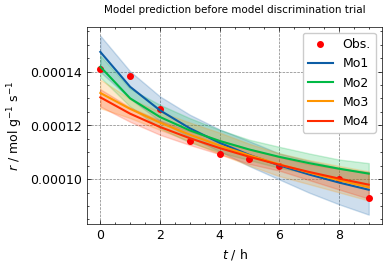

In [13]:
interactive(0, 4)
plt.title("Model prediction before model discrimination trial")

Array([ 600.,    9.,    4., 1000., 1000.,    1.], dtype=float32)

(10, 1, 1, 25)

Text(0.5, 1.0, 'Model prediction at model discrimination trial')

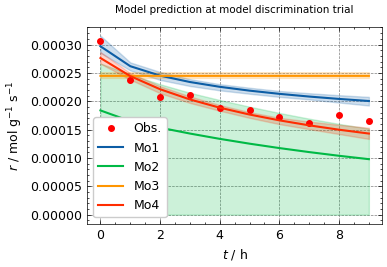

In [14]:
interactive(3, 8)
plt.title("Model prediction at model discrimination trial")

/tmp/ipykernel_67076/1707754344.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



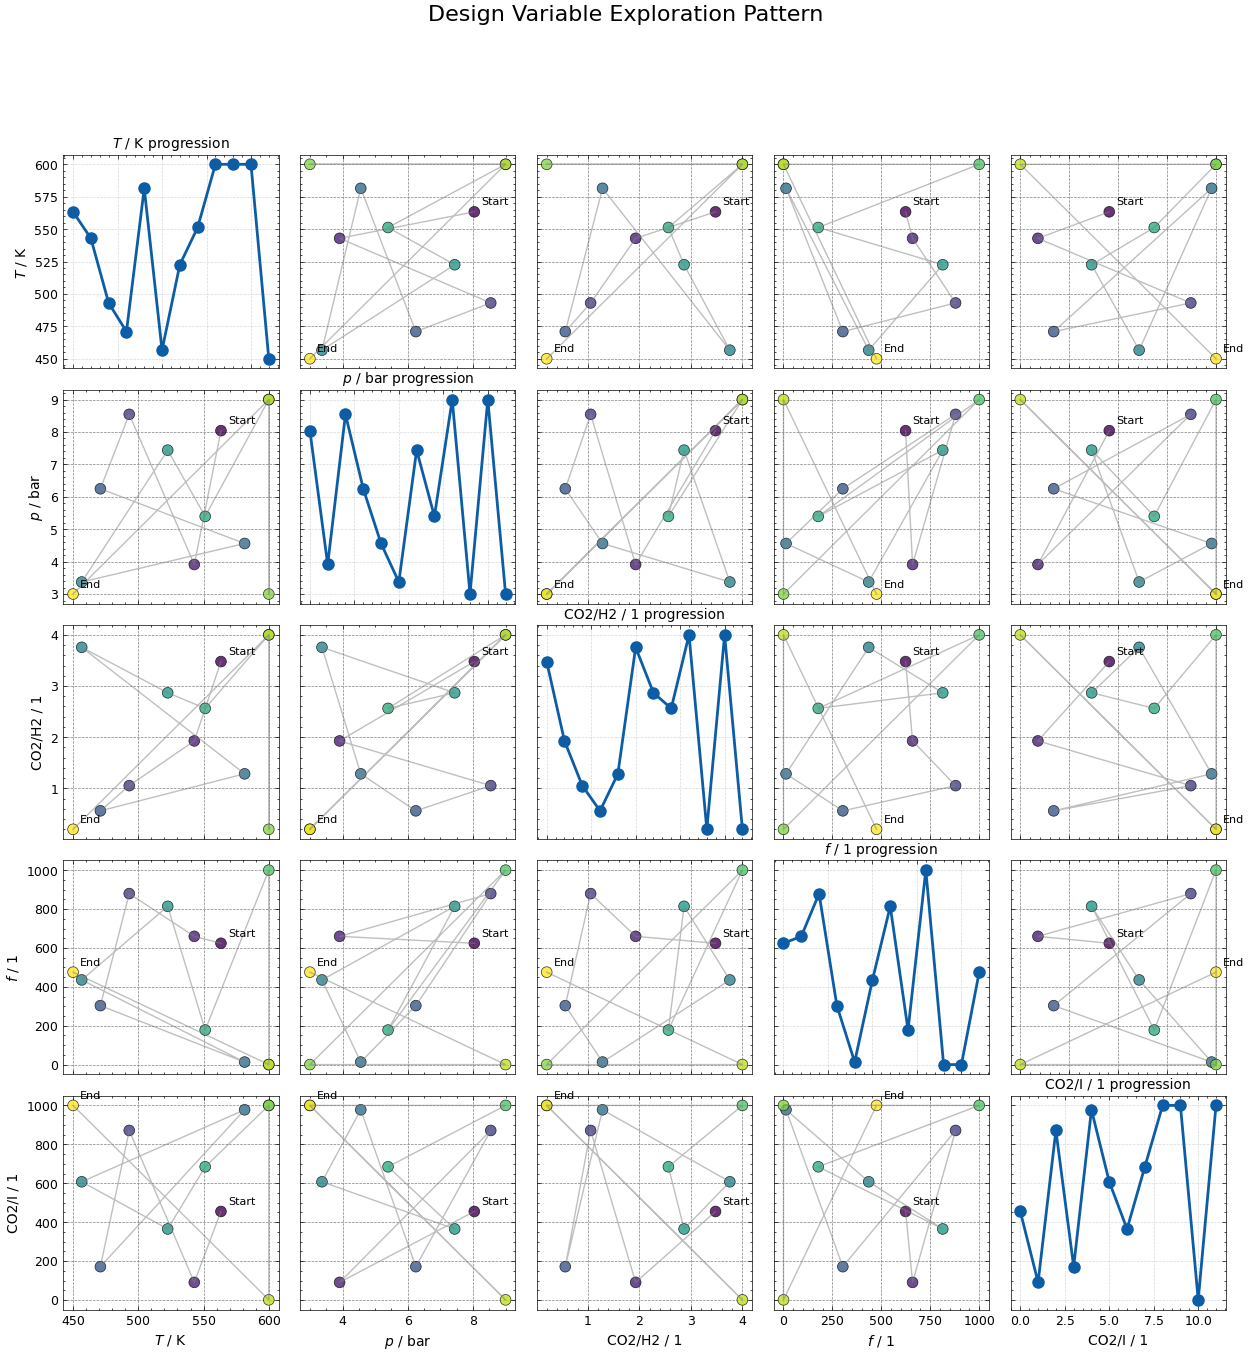

In [15]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = jnp.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## claculate the RMSE

In [16]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_D_004.nc"))
display(test_data)

<xarray.Dataset> Size: 160kB
Dimensions:    (sample: 1000, parameter: 6, species: 5, time: 10, component: 1,
                draws: 1)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
  * time       (time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * component  (component) <U1 4B 'a'
  * draws      (draws) int64 8B 0
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float32 4kB ...
    p          (sample, species) float32 20kB ...
    latent_r   (time, sample, component, draws) float32 40kB ...
    obs_r      (time, sample, component, draws) float32 40kB ...
Attributes:
    noise:    homoscedastic
    sigma:    1e-05

In [17]:
postdatas = {
    "Mo1": [],
    "Mo2": [],
    "Mo3": [],
    "Mo4": [],
}
for model_name, model_idatas in idatas.items():
    for i, idata in enumerate(model_idatas):
        postdata = validate_funs[model_name](idata, test_data, num_samples=985)
        postdatas[model_name].append(postdata)

(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


...

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



In [18]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[
        var_name
    ].values  # shape (chain=1, draw=1, obs, times=10, 1)
    pred = postdata.posterior_predictive[
        var_name
    ].values  # shape (chain=1, draw, obs, times=10, n_samples)
    res = true - pred
    rmse_vals = jnp.sqrt(jnp.mean(res**2, axis=(2, 3, 4))).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da

In [19]:
RMSEs = {
    "Mo1": [],
    "Mo2": [],
    "Mo3": [],
    "Mo4": [],
}
for model_name, postdatas_list in postdatas.items():
    for postdata in postdatas_list:
        RMSEs[model_name].append(bRMSE(postdata, "r_lat"))
    RMSEs[model_name] = jnp.array(RMSEs[model_name])

In [20]:
print(RMSEs)

{'Mo1': Array([[3.0317492e-06, 2.4365709e-06, 4.1134876e-06, ..., 3.5892897e-06,
        2.7009005e-06, 2.8013537e-06],
       [2.8970092e-06, 3.4922539e-06, 2.8561217e-06, ..., 3.3611286e-06,
        3.0407505e-06, 2.7225940e-06],
       [3.1583195e-06, 3.4902234e-06, 3.3096392e-06, ..., 4.7540957e-06,
        3.4720547e-06, 3.6488361e-06],
       [6.2411295e-06, 5.9023478e-06, 7.4765840e-06, ..., 6.6767207e-06,
        5.9731369e-06, 7.3306965e-06],
       [6.1295773e-06, 6.2610811e-06, 6.8508775e-06, ..., 7.4579243e-06,
        7.0456690e-06, 7.8375524e-06]], dtype=float32), 'Mo2': Array([[4.00069848e-06, 3.58503689e-06, 5.29023600e-06, ...,
        7.35702724e-06, 6.65594644e-06, 3.74523097e-06],
       [5.64915035e-06, 5.29585714e-06, 5.58541342e-06, ...,
        4.95338372e-06, 6.24129098e-05, 4.88454953e-06],
       [3.95537745e-06, 3.55209932e-06, 4.01807483e-06, ...,
        4.44055149e-06, 3.67948951e-06, 3.70642965e-06],
       [1.04018709e-05, 8.20308924e-06, 1.04483115e-05

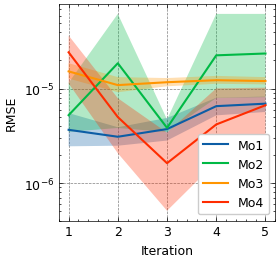

In [21]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(jnp.arange(1, len(RMSEs["Mo1"]) + 1), RMSEs["Mo1"].mean(axis=1), label="Mo1")
ax.fill_between(
    jnp.arange(1, len(RMSEs["Mo1"]) + 1),
    jnp.quantile(RMSEs["Mo1"], 0.025, axis=1),
    jnp.quantile(RMSEs["Mo1"], 0.975, axis=1),
    alpha=0.3,
)
ax.plot(jnp.arange(1, len(RMSEs["Mo2"]) + 1), RMSEs["Mo2"].mean(axis=1), label="Mo2")
ax.fill_between(
    jnp.arange(1, len(RMSEs["Mo2"]) + 1),
    jnp.quantile(RMSEs["Mo2"], 0.025, axis=1),
    jnp.quantile(RMSEs["Mo2"], 0.975, axis=1),
    alpha=0.3,
)
ax.plot(jnp.arange(1, len(RMSEs["Mo3"]) + 1), RMSEs["Mo3"].mean(axis=1), label="Mo3")
ax.fill_between(
    jnp.arange(1, len(RMSEs["Mo3"]) + 1),
    jnp.quantile(RMSEs["Mo3"], 0.025, axis=1),
    jnp.quantile(RMSEs["Mo3"], 0.975, axis=1),
    alpha=0.3,
)

ax.plot(jnp.arange(1, len(RMSEs["Mo4"]) + 1), RMSEs["Mo4"].mean(axis=1), label="Mo4")
ax.fill_between(
    jnp.arange(1, len(RMSEs["Mo4"]) + 1),
    jnp.quantile(RMSEs["Mo4"], 0.025, axis=1),
    jnp.quantile(RMSEs["Mo4"], 0.975, axis=1),
    alpha=0.3,
)

ax.legend()